# Paso 6 · El Nichols chart (con Python)

Notebook del **Paso 6**: el mismo número complejo $L$, pero en coordenadas (fase, dB). Allí **multiplicar es sumar** y $|T|$ se lee con contornos.

| Concepto matemático | Concepto de programación |
|---|---|
| $L\mapsto(\angle L,\,|L|_{\rm dB})$ | función de cambio de coordenadas |
| contorno de $|T|$ constante | ecuación de 2.º grado en $|L|$, `np.roots`-like |
| la carta de Nichols | mallas de contornos con `matplotlib` |
| márgenes de fase y de ganancia | búsqueda de cruces con `np.argmin` |
| subir/bajar ganancia, añadir retardo | traslaciones verticales/horizontales |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from nbhelp import db, fase, wrapfase, carta_nichols, AZUL, NARANJA, TINTA, GRIS
ang = lambda z: np.degrees(np.angle(z))
T_de = lambda L: L / (1 + L)

## 1. El mismo número, otras coordenadas

$L=|L|e^{j\varphi}\;\longmapsto\;(\varphi,\;20\log_{10}|L|)$. Ventaja: si $L=G\cdot P$, entonces $\varphi_L=\varphi_G+\varphi_P$ y $|L|_{\rm dB}=|G|_{\rm dB}+|P|_{\rm dB}$. **Multiplicar por un controlador = desplazar el punto.**

## 2. Dado un punto del mapa, ¿cuánto vale $|T|$?

Con $\theta$ la fase y $r=|L|$: $\;|T|=\dfrac{r}{\sqrt{1+2r\cos\theta+r^2}}$. Rellenamos el mapa en nueve puntos:

In [3]:
def Tdb_punto(fase_deg, mod_db):
    L = 10**(mod_db/20) * np.exp(1j*np.radians(fase_deg))
    return np.inf if abs(1 + L) < 1e-9 else db(T_de(L))

fases = [-270, -180, -90]
mods = [20, 0, -20]
print("|T| en dB; filas = |L| (dB), columnas = fase de L")
print(f"{'':>8}" + "".join(f"{f:>9}°" for f in fases))
for m in mods:
    print(f"{m:>5} dB " + "".join(f"{Tdb_punto(f, m):>10.2f}" for f in fases))

|T| en dB; filas = |L| (dB), columnas = fase de L
             -270°     -180°      -90°
   20 dB      -0.04      0.92     -0.04
    0 dB      -3.01       inf     -3.01
  -20 dB     -20.04    -19.08    -20.04


Lectura: lejos del punto crítico $(-180^\circ,0\ \text{dB})$ y por encima, $|T|\approx0$ dB; por debajo, $|T|\approx|L|$; **en el propio punto crítico, $|T|\to\infty$**.

## 3. La carta de Nichols

Un contorno de $|T|=M$ es el conjunto de $(\varphi,r)$ que cumple $(1-M^2)r^2-2M^2\cos\varphi\,r-M^2=0$ — se resuelve en cada fase. La función `carta_nichols` (en `nbhelp.py`) lo dibuja:

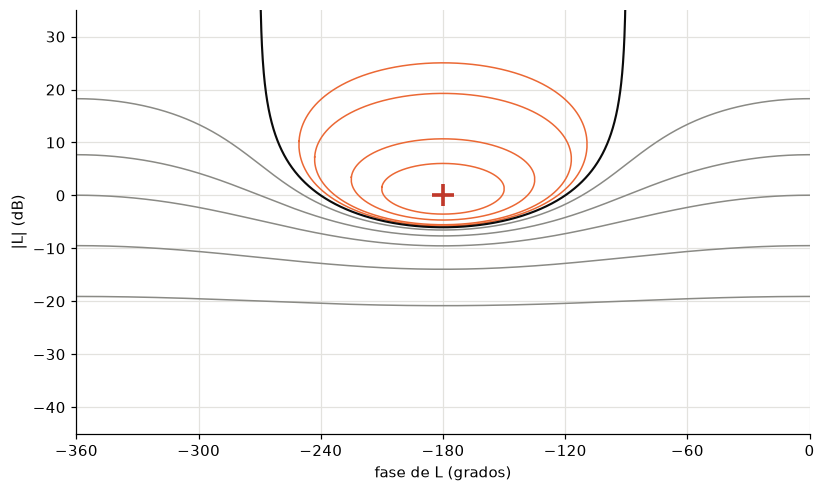

In [4]:
fig, ax = plt.subplots(figsize=(8.6, 5))
carta_nichols(ax, (-360, 0), (-45, 35))
ax.set_xticks(range(-360, 1, 60)); plt.show()

## 4. Un lazo real sobre la carta

$L(s)=\dfrac{3}{s(1+s/2)(1+s/10)}$ (el del Paso 5). Cada $\omega$ es un punto; unidos, una curva.

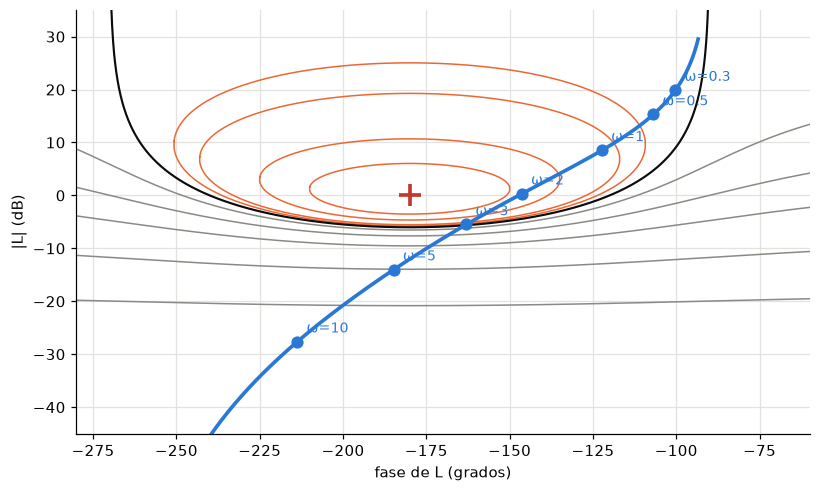

pico de |T| = 5.10 dB en ω = 2.16   (diapositivas: 5.1 dB cerca de ω = 2)


In [5]:
L = lambda s: 3 / (s*(1 + s/2)*(1 + s/10))
w = np.logspace(-1, 1.7, 3000); z = L(1j*w)
fig, ax = plt.subplots(figsize=(8.6, 5)); carta_nichols(ax, (-280, -60), (-45, 35))
ax.plot(fase(z), db(z), color=AZUL, lw=2.4, zorder=4)
for wv in (0.3, 0.5, 1, 2, 3, 5, 10):
    zz = L(1j*wv); p = float(wrapfase(zz))
    ax.plot(p, db(zz), "o", color=AZUL, ms=7); ax.annotate(f"ω={wv:g}", (p, db(zz)), xytext=(6, 6), textcoords="offset points", fontsize=9, color=AZUL)
plt.show()

T = np.abs(T_de(z)); i = np.argmax(T)
print(f"pico de |T| = {db(T[i]):.2f} dB en ω = {w[i]:.2f}   (diapositivas: 5.1 dB cerca de ω = 2)")

## 5. Márgenes de estabilidad en el Nichols

- **Margen de fase**: en el cruce de 0 dB, cuánta fase falta para $-180^\circ$.
- **Margen de ganancia**: en el cruce de $-180^\circ$, cuántos dB faltan para 0 dB.

In [6]:
w = np.logspace(-2, 3, 200000); z = L(1j*w)
i = np.argmin(np.abs(db(z)));            pm = 180 + ang(z[i])
j = np.argmin(np.abs(fase(z) + 180));    gm = -db(z[j])
print(f"cruce de 0 dB   : ω = {w[i]:.3f} rad/s  -> margen de fase    = {pm:.1f}°")
print(f"cruce de -180°  : ω = {w[j]:.3f} rad/s  -> margen de ganancia = {gm:.1f} dB")

cruce de 0 dB   : ω = 2.051 rad/s  -> margen de fase    = 32.7°
cruce de -180°  : ω = 4.472 rad/s  -> margen de ganancia = 12.0 dB


## 6. Mover la curva: ganancia y retardo

- Multiplicar por $K$ **sube/baja** la curva ($20\log_{10}K$ dB) sin cambiar la fase.
- Un retardo $T_d$ la **empuja a la izquierda** ($-\omega T_d$ rad), más cuanto mayor es $\omega$.

In [7]:
def margen_fase(Lf):
    w = np.logspace(-2, 3, 100000); z = Lf(1j*w); i = np.argmin(np.abs(db(z)))
    return w[i], 180 + ang(z[i])

print(f"{'caso':<28}{'ωc':>8}{'MF (°)':>10}")
for nombre, f in [("L original", L),
                  ("ganancia ×2 (+6 dB)", lambda s: 2*L(s)),
                  ("ganancia ×0.5 (−6 dB)", lambda s: 0.5*L(s)),
                  ("retardo 0.1 s", lambda s: L(s)*np.exp(-0.1*s))]:
    wc, mf = margen_fase(f); print(f"{nombre:<28}{wc:>8.2f}{mf:>10.1f}")

caso                              ωc    MF (°)
L original                      2.05      32.7
ganancia ×2 (+6 dB)             3.10      15.6
ganancia ×0.5 (−6 dB)           1.26      50.6
retardo 0.1 s                   2.05      20.9


Más ganancia ⇒ cruce más a la derecha y **menos** margen; el retardo resta fase donde más duele (alta $\omega$).

## 7. El puente hacia QFT: la incertidumbre es una nube de puntos

Si $P$ no se conoce exactamente, en **cada** $\omega$ la planta ya no es un punto sino una **nube** en el mapa (Paso 7). El controlador la desplaza entera; las especificaciones dicen en qué zona del mapa puede estar el punto nominal para que *toda* la nube sea aceptable (Paso 8).

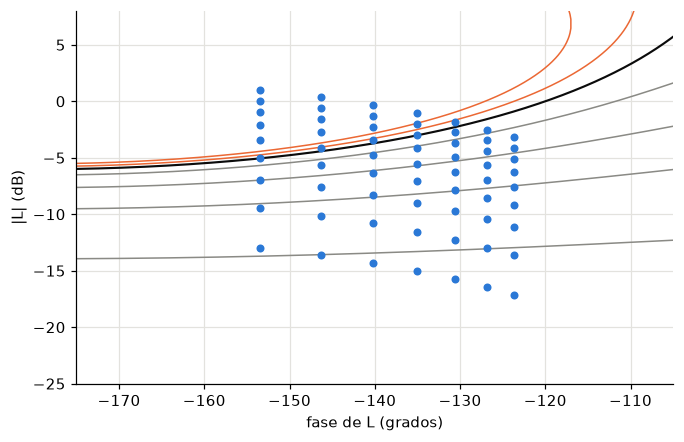

la nube mide 29.7° de ancho y 18.1 dB de alto


In [8]:
# Anticipo: la planta K/(s(s+a)), K en [1,5], a en [1,3], en ω = 2
Kv, av = np.meshgrid(np.linspace(1, 5, 9), np.linspace(1, 3, 7))
Pnube = Kv.ravel() / (1j*2 * (1j*2 + av.ravel()))
fig, ax = plt.subplots(figsize=(7, 4.4)); carta_nichols(ax, (-175, -105), (-25, 8), niveles=(1, 0.5, 0, -1, -3, -6, -12))
ax.scatter(wrapfase(Pnube), db(Pnube), s=18, color=AZUL, zorder=5); plt.show()
print(f"la nube mide {np.ptp(wrapfase(Pnube)):.1f}° de ancho y {np.ptp(db(Pnube)):.1f} dB de alto")

## 8. Ejercicio del Paso 6

$L=1\angle-135^\circ$ (el del Paso 5).

1. ¿Coordenadas en el mapa de Nichols?
2. Estima $|T|$ y compáralo con $2.32$ dB.
3. Sube $6$ dB ($L=2\angle-135^\circ$) y vuelve a leer; después bájale $6$ dB. ¿Qué observas?

**Tu turno.**

In [9]:
# 1) coordenadas (fase, dB)
# 2) |T| con Tdb_punto
# 3) tres posiciones en la vertical -135°: +6, 0, -6 dB
# escribe aquí tu código

In [10]:
print("1) coordenadas: (-135°, 0 dB)")
for m in (db(2), 0, db(0.5)):
    print(f"   |L| = {m:+.1f} dB, -135°  ->  |T| = {Tdb_punto(-135, m):6.2f} dB")
print("2) en (-135°, 0 dB): |T| = 2.32 dB, igual que el cálculo del Paso 5")
print("3) con la fase fija en -135°, |T| SUBE al subir la ganancia (2.32 -> 2.65 dB) pero con rendimientos decrecientes;")
print("   a la baja, |T| ≈ |L| y cae casi dB por dB (2.32 -> -3.37 dB).")
assert np.isclose(Tdb_punto(-135, db(2)), 2.65, atol=0.01) and np.isclose(Tdb_punto(-135, db(0.5)), -3.37, atol=0.01)
assert np.isclose(Tdb_punto(-135, 0), 2.32, atol=0.01)

1) coordenadas: (-135°, 0 dB)
   |L| = +6.0 dB, -135°  ->  |T| =   2.65 dB
   |L| = +0.0 dB, -135°  ->  |T| =   2.32 dB
   |L| = -6.0 dB, -135°  ->  |T| =  -3.37 dB
2) en (-135°, 0 dB): |T| = 2.32 dB, igual que el cálculo del Paso 5
3) con la fase fija en -135°, |T| SUBE al subir la ganancia (2.32 -> 2.65 dB) pero con rendimientos decrecientes;
   a la baja, |T| ≈ |L| y cae casi dB por dB (2.32 -> -3.37 dB).


## 9. Resumen

- Nichols = $(\angle L,\ |L|_{\rm dB})$: ganancia = desplazar en vertical, fase/retardo = en horizontal.
- Los contornos de $|T|$ constante son una carta fija; el punto crítico es $(-180^\circ,0\ {\rm dB})$.
- Pico de $|T|$ ⇔ la curva pasa cerca del punto crítico ⇔ margen de fase/ganancia pequeño.
- Con incertidumbre cada $\omega$ es una **nube** de puntos: eso son los templates del Paso 7.